In [ ]:
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

# fetch dataset
heart_disease = fetch_ucirepo(id=45)

# data (as pandas dataframes)
X = heart_disease.data.features
y = heart_disease.data.targets

# metadata
print(heart_disease.metadata)

# variable information
print(heart_disease.variables)


{'uci_id': 45, 'name': 'Heart Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/45/data.csv', 'abstract': '4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 303, 'num_features': 13, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['num'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C52P4X', 'creators': ['Andras Janosi', 'William Steinbrunn', 'Matthias Pfisterer', 'Robert Detrano'], 'intro_paper': {'ID': 231, 'type': 'NATIVE', 'title': 'International application of a new probability algorithm for the diagnosis of coronary artery disease.', 'authors': 'R. Detrano, A. Jánosi, W. Steinbrunn, M

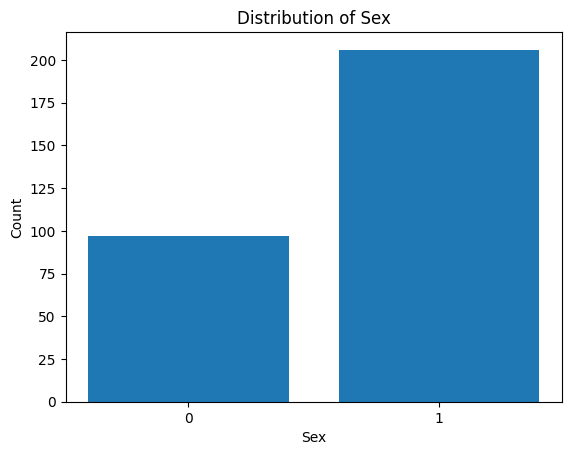

In [ ]:
import matplotlib.pyplot as plt

# Count occurrences of each category in "sex"
sex_counts = X["sex"].value_counts().sort_index()

# Create bar plot
plt.bar(sex_counts.index, sex_counts.values)

# Format x-axis to show only 0 and 1 without decimals
plt.xticks([0, 1], ["0", "1"])

# Labels and title
plt.xlabel("Sex")
plt.ylabel("Count")
plt.title("Distribution of Sex")

# Show plot
plt.show()

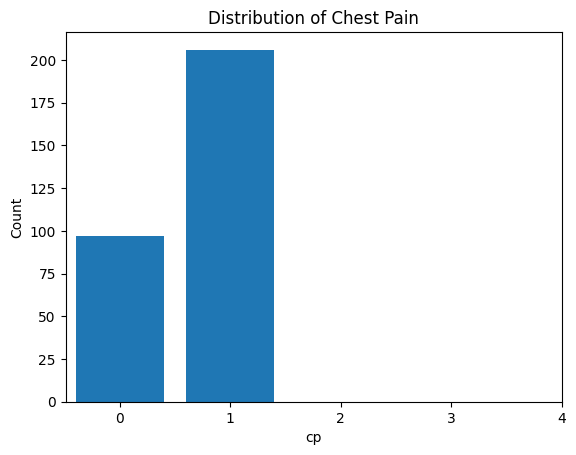

In [ ]:
import matplotlib.pyplot as plt

# Count occurrences of each category in "sex"
cp_counts = X["cp"].value_counts().sort_index()

# Create bar plot
plt.bar(sex_counts.index, sex_counts.values)

# Format x-axis to show only 0 and 1 without decimals
plt.xticks([0, 1, 2, 3, 4], ["0", "1", "2", "3", "4"])

# Labels and title
plt.xlabel("cp")
plt.ylabel("Count")
plt.title("Distribution of Chest Pain")

# Show plot
plt.show()

In [ ]:
X

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,1,110,264,0,0,132,0,1.2,2,0.0,7.0
299,68,1,4,144,193,1,0,141,0,3.4,2,2.0,7.0
300,57,1,4,130,131,0,0,115,1,1.2,2,1.0,7.0
301,57,0,2,130,236,0,2,174,0,0.0,2,1.0,3.0


In [ ]:
y

,num
0,0
1,2
2,1
3,0
4,0
...,...
298,1
299,2
300,3
301,1


In [ ]:
import numpy as np
X_no_nan = np.nan_to_num(X, nan=0)

In [ ]:
import imblearn
from imblearn.over_sampling import SMOTE
oversample = SMOTE()
X, y = oversample.fit_resample(X_no_nan, y)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, classification_report
from sklearn.decomposition import PCA
from matplotlib.colors import ListedColormap

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)



In [ ]:
# Initialize and train the Logistic Regression model
clf = LogisticRegression(random_state=0, solver='lbfgs')
clf.fit(X_train, y_train)

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(random_state=0)

In [ ]:
# Make predictions on the test set
y_pred = clf.predict(X_test)

In [ ]:
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

f1 = f1_score(y_test, y_pred, average='weighted')
print("F1 Score:", f1)

roc_auc_score(y_test, clf.predict_proba(X_test), multi_class='ovr')
AUC = roc_auc_score(y_test, clf.predict_proba(X_test), multi_class='ovr')
print("Area Under the Curve Score:", AUC)

recall = recall_score(y_test, y_pred, average="micro")
#print("Recall:", recall)

precision = precision_score(y_test, y_pred, average="weighted")
#print("Precision:", precision)

print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=clf.classes_)
disp.plot()

plt.show()

Accuracy: 0.774390243902439


TypeError: 'float' object is not callable

In [ ]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
svm_clf = make_pipeline(StandardScaler(), SVC(gamma='auto'))
svm_clf.fit(X_train, y_train)
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

#Predict
y_pred = svm_clf.predict(X_test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)

#Score
acc = accuracy_score(y_test, y_pred)
print("Accuracy:", acc)
f1_score = f1_score(y_test, y_pred, labels=None, pos_label=1, average='weighted')
print("F1 score:", f1_score)
roc_auc_score(y_test, svm_clf.predict_proba(X_test), multi_class='ovr')
AUC = roc_auc_score(y_test, svm_clf.predict_proba(X_test), multi_class='ovr')
print("Area Under the Curve Score:", AUC)
#print ("Recall:", recall_score(y_test, y_pred,average="micro"))
#print ("Precision:", precision_score(y_test, y_pred, average="micro"))
print ("\n clasification report: \n", classification_report(y_test, y_pred))
print ('\n confussion matrix:\n',confusion_matrix(y_test, y_pred))
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=clf.classes_)
disp.plot()

plt.show()

Accuracy: 0.774390243902439
F1 score: 0.7681257396743119


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


AttributeError: This 'Pipeline' has no attribute 'predict_proba'

/usr/local/lib/python3.11/dist-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


Accuracy: 0.7378048780487805
F1 score: 0.7428227718026724
Area Under the Curve Score: 0.8993907184139573

 clasification report: 
               precision    recall  f1-score   support

           0       0.59      0.61      0.60        28
           1       0.63      0.77      0.69        35
           2       0.71      0.77      0.74        35
           3       0.89      0.73      0.80        33
           4       0.96      0.79      0.87        33

    accuracy                           0.74       164
   macro avg       0.76      0.73      0.74       164
weighted avg       0.76      0.74      0.74       164


 confussion matrix:
 [[17  7  3  1  0]
 [ 3 27  3  2  0]
 [ 3  5 27  0  0]
 [ 3  3  2 24  1]
 [ 3  1  3  0 26]]


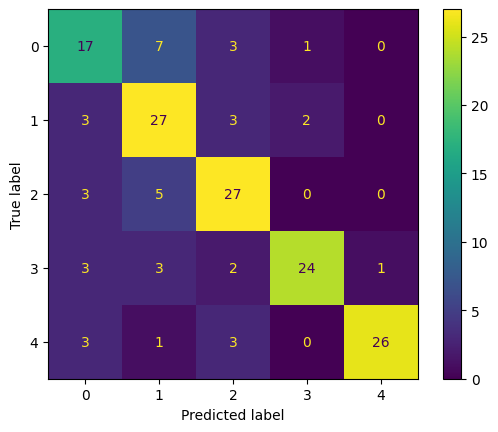

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
neigh = KNeighborsClassifier(n_neighbors=2)
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
neigh.fit(X_train, y_train)

#Predict
y_pred = neigh.predict(X_test)
#X_train, X_test, y_train, y_test = train_test_split(
    #X, y, test_size=0.20, random_state=42)

#Score
acc= 0
acc = accuracy_score(y_test, y_pred)
print("Accuracy:", acc)
f1_score = f1_score(y_test, y_pred, labels=None, pos_label=1, average='weighted')
print("F1 score:", f1_score)
roc_auc_score(y_test, neigh.predict_proba(X_test), multi_class='ovr')
AUC = roc_auc_score(y_test, neigh.predict_proba(X_test), multi_class='ovr')
print("Area Under the Curve Score:", AUC)
#print ("Recall:", recall_score(y_test, y_pred,average="micro"))
#print ("Precision:", precision_score(y_test, y_pred, average="micro"))
print ("\n clasification report: \n", classification_report(y_test, y_pred))
print ('\n confussion matrix:\n',confusion_matrix(y_test, y_pred))
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=clf.classes_)
disp.plot()

plt.show()

/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:1124: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Accuracy: 0.4817073170731707
F1 score: 0.432733100726073
Area Under the Curve Score:  0.8185916116200364

 clasification report: 
               precision    recall  f1-score   support

           0       0.71      0.79      0.75        28
           1       0.60      0.17      0.27        35
           2       0.34      0.74      0.47        35
           3       1.00      0.09      0.17        33
           4       0.50      0.67      0.57        33

    accuracy                           0.48       164
   macro avg       0.63      0.49      0.44       164
weighted avg       0.62      0.48      0.43       164


 confussion matrix:
 [[22  1  5  0  0]
 [ 7  6 16  0  6]
 [ 2  0 26  0  7]
 [ 0  2 19  3  9]
 [ 0  1 10  0 22]]


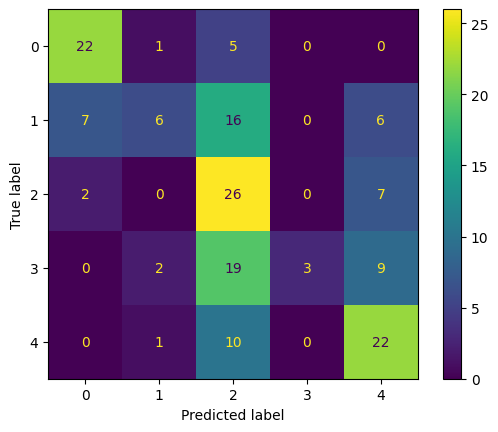

Feature 9: Importance 0.07439024390243902
Feature 6: Importance 0.06239837398373983
Feature 7: Importance 0.05548780487804879
Feature 11: Importance 0.03617886178861787
Feature 5: Importance 0.0339430894308943
Feature 3: Importance 0.029268292682926817
Feature 12: Importance 0.029065040650406493
Feature 4: Importance 0.027845528455284548
Feature 8: Importance 0.024186991869918684
Feature 0: Importance 0.018292682926829246
Feature 2: Importance 0.009959349593495941
Feature 1: Importance -0.00040650406504065263
Feature 10: Importance -0.003658536585365857


In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
mlp = MLPClassifier(random_state=1, max_iter=300)
mlp.fit(X_train, y_train)

#Predict
y_pred = mlp.predict(X_test)

#Score
acc= 0
acc = accuracy_score(y_test, y_pred)
print("Accuracy:", acc)
f1_score = f1_score(y_test, y_pred, labels=None, pos_label=1, average='weighted')
print("F1 score:", f1_score)
from sklearn.metrics import roc_auc_score
roc_auc_score(y_test, mlp.predict_proba(X_test), multi_class='ovr')
AUC = roc_auc_score(y_test, mlp.predict_proba(X_test), multi_class='ovr')
print("Area Under the Curve Score: ", AUC)
#print ("Recall:", recall_score(y_test, y_pred,average="micro"))
#print ("Precision:", precision_score(y_test, y_pred, average="micro"))
print ("\n clasification report: \n", classification_report(y_test, y_pred))
print ('\n confussion matrix:\n',confusion_matrix(y_test, y_pred))

import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=clf.classes_)
disp.plot()

plt.show()
from sklearn.inspection import permutation_importance
r = permutation_importance(mlp, X_test, y_test, scoring='accuracy',
                            n_repeats=30,
                           random_state=0)
feature_importances = r.importances_mean

sorted_idx = np.argsort(feature_importances)[::-1]

for idx in sorted_idx:
  print(f"Feature {idx}: Importance {feature_importances[idx]}")

/usr/local/lib/python3.11/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Accuracy is  0.5365853658536586
f1 score is  0.5062855231821854
Area Under the Curve Score: 0.7892484410932685

 clasification report: 
               precision    recall  f1-score   support

           0       0.71      0.96      0.82        28
           1       0.50      0.31      0.39        35
           2       0.53      0.29      0.37        35
           3       0.55      0.36      0.44        33
           4       0.44      0.85      0.58        33

    accuracy                           0.54       164
   macro avg       0.55      0.56      0.52       164
weighted avg       0.54      0.54      0.51       164


 confussion matrix:
 [[27  0  1  0  0]
 [ 5 11  5  3 11]
 [ 3  3 10  5 14]
 [ 2  6  3 12 10]
 [ 1  2  0  2 28]]


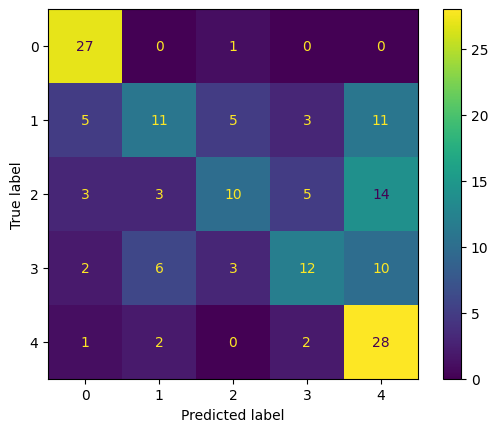

array([0.01445087, 0.03753673, 0.11765357, 0.01542099, 0.00930494,
       0.00932638, 0.04021936, 0.04454613, 0.06634944, 0.13964237,
       0.14613156, 0.16914814, 0.19026951])

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
rand = RandomForestClassifier(max_depth=2, random_state=42)
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)
rand.fit(X_train, y_train)

y_pred = rand.predict(X_test)

#Score
acc= 0
acc = accuracy_score(y_test, y_pred)
print("Accuracy is ", acc)
f1_score = f1_score(y_test, y_pred, labels=None, pos_label=1, average='weighted')
print("f1 score is ", f1_score)
roc_auc_score(y_test, rand.predict_proba(X_test), multi_class='ovr')
AUC = roc_auc_score(y_test, rand.predict_proba(X_test), multi_class='ovr')
print("Area Under the Curve Score:", AUC)
#print ("Recall:", recall_score(y_test, y_pred,average="micro"))
#print ("Precision:", precision_score(y_test, y_pred, average="micro"))
print ("\n clasification report: \n", classification_report(y_test, y_pred))
print ('\n confussion matrix:\n',confusion_matrix(y_test, y_pred))
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=clf.classes_)
disp.plot()

plt.show()

rand.feature_importances_

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE  # pip install imbalanced-learn if needed

# Assume you have your data loaded in variables X and y (for example, from a CSV)
# For demonstration, X and y should be defined here:
# X, y = your_data_features, your_data_labels

# Split data into training and testing sets.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the features.
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Use SMOTE to augment the training data if classes are imbalanced.
smote = SMOTE(random_state=1)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)


# Build a deeper Keras model with dropout layers.
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.1),  # 20% dropout for regularization.
    Dense(64, activation='relu'),
    Dropout(0.1),
    Dense(1, activation='sigmoid')  # For binary classification.
])

# Compile the model.
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Set up early stopping to prevent overfitting.
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Train the model using the augmented data.
history = model.fit(
    X_train_resampled,
    y_train_resampled,
    epochs=150,            # Increase the number of epochs.
    batch_size=32,
    validation_split=0.05,  # Use 20% of the (augmented) training data as validation.
    callbacks=[early_stop]
)

# Predict on the test set.
# The model outputs probabilities, so we convert them to class labels using a threshold of 0.5.
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype("int32").flatten()

# Evaluate the model's performance.
acc = accuracy_score(y_test, y_pred)
print("Accuracy is:", acc)

f1 = f1_score(y_test, y_pred, average='weighted')
print("F1 score is:", f1)

recall = recall_score(y_test, y_pred, average='micro')
print("Recall is:", recall)

precision = precision_score(y_test, y_pred, average='micro')
print("Precision is:", precision)

print("\nClassification report:\n", classification_report(y_test, y_pred))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))


In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=clf.classes_)
disp.plot()

plt.show()